<a href="https://colab.research.google.com/github/annaizyurieva-stack/IDP-Project-Diabetics/blob/3-%D1%8D%D1%82%D0%B0%D0%BF/3_%D1%8D%D1%82%D0%B0%D0%BF_%D1%87%D0%B0%D1%81%D1%82%D1%8C_1_%D0%B0%D0%BD%D0%B0%D0%BB%D0%B8%D0%B7_%D0%B4%D0%B0%D0%BD%D0%BD%D1%8B%D1%85_%D0%98%D0%B7%D1%8E%D1%80%D1%8C%D0%B5%D0%B2%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Этап 3. Часть 1 — Анализ данных (EDA и проверка гипотез)

**Датасет:** Pima Indians Diabetes, очищенная версия `diabetes_clean.csv` из этапа 2 (768 пациенток, 8 признаков, цель `Outcome`: 1 — диабет есть, 0 — нет) + два флага `Insulin_was_missing`, `SkinThickness_was_missing`.

**План (по заданию)**
1. Взять 25% датасета случайным образом — это «разведочная» часть. Остальные 75% не трогаем до проверки гипотез.
2. Построить графики, посчитать среднее и медиану.
3. По графикам сформулировать гипотезы и описать, как к ним пришли.
4. Проверить гипотезы на оставшихся 75%.
5. Сделать вывод.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

TARGET = "Outcome"
RANDOM_STATE = 42

## 0. Загрузка данных

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()            # загружаем diabetes_clean.csv
    DATA_PATH = list(uploaded.keys())[0]
except ImportError:
    DATA_PATH = "diabetes_clean.csv"     # локальный запуск

df = pd.read_csv(DATA_PATH)
print("Строк:", df.shape[0], "| Столбцов:", df.shape[1])
df.head()

Saving diabetes_clean.csv to diabetes_clean.csv
Строк: 768 | Столбцов: 11


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,Insulin_was_missing,SkinThickness_was_missing
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1,1,0
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0,1,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1,1,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,0,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1,0,0


## 1. Разделение: 25% для исследования, 75% для проверки

Берём **25% строк случайным образом** (`random_state=42`, чтобы результат воспроизводился). Случайная выборка лучше «первых строк подряд»: если в файле есть порядок, срез подряд может оказаться смещённым.

Гипотезы мы будем искать только на `explore`, а проверять только на `holdout`. Если бы мы проверяли гипотезу на тех же данных, на которых её придумали, подтверждение было бы почти гарантированным и ничего бы не доказывало.

In [3]:
explore = df.sample(frac=0.25, random_state=RANDOM_STATE)   # 25% — смотрим, ищем идеи
holdout = df.drop(explore.index)                            # 75% — только проверка

print(f"explore: {len(explore)} строк ({len(explore)/len(df):.0%}) | holdout: {len(holdout)} строк ({len(holdout)/len(df):.0%})")
print(f"Доля диабета: весь датасет {df[TARGET].mean():.1%} | explore {explore[TARGET].mean():.1%} | holdout {holdout[TARGET].mean():.1%}")

explore: 192 строк (25%) | holdout: 576 строк (75%)
Доля диабета: весь датасет 34.9% | explore 35.9% | holdout 34.5%


Доли класса «диабет есть» в двух частях близки, значит выборка не смещена по целевой переменной.

## 2. Среднее и медиана

Если среднее заметно больше медианы, у признака длинный правый хвост (несколько больших значений тянут среднее вверх) — как в примере из лекции про «одного пациента».

In [4]:
NUM = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]

summary = pd.DataFrame({
    "среднее": explore[NUM].mean(),
    "медиана": explore[NUM].median(),
})
summary["среднее − медиана"] = summary["среднее"] - summary["медиана"]
summary["среднее / медиана"] = summary["среднее"] / summary["медиана"]
summary.round(2)

,среднее,медиана,среднее − медиана,среднее / медиана
Pregnancies,4.16,3.00,1.16,1.39
Glucose,121.60,115.00,6.60,1.06
BloodPressure,72.78,72.00,0.78,1.01
SkinThickness,30.18,29.00,1.18,1.04
Insulin,141.91,125.00,16.91,1.14
BMI,32.87,32.55,0.32,1.01
DiabetesPedigreeFunction,0.48,0.37,0.11,1.29
Age,34.20,29.00,5.20,1.18


**Что видно.**
- `BMI` (32.9 и 32.6), `BloodPressure` (72.8 и 72.0): среднее ≈ медиана — распределения примерно симметричны.
- `Age` (34.2 против 29), `Pregnancies` (4.2 против 3), `DiabetesPedigreeFunction` (0.48 против 0.37), `Glucose` (121.6 против 115): среднее больше медианы, у признаков правый хвост.
- `Insulin` и `SkinThickness`: у этих признаков медиана — это значение, которым мы на этапе 2 заполнили скрытые пропуски (около 49% и 30% строк), поэтому медиана здесь частично «искусственная», и к выводам по этим двум признакам нужно относиться осторожнее.

## 3. Графики

### График 1. Распределения признаков со средним и медианой

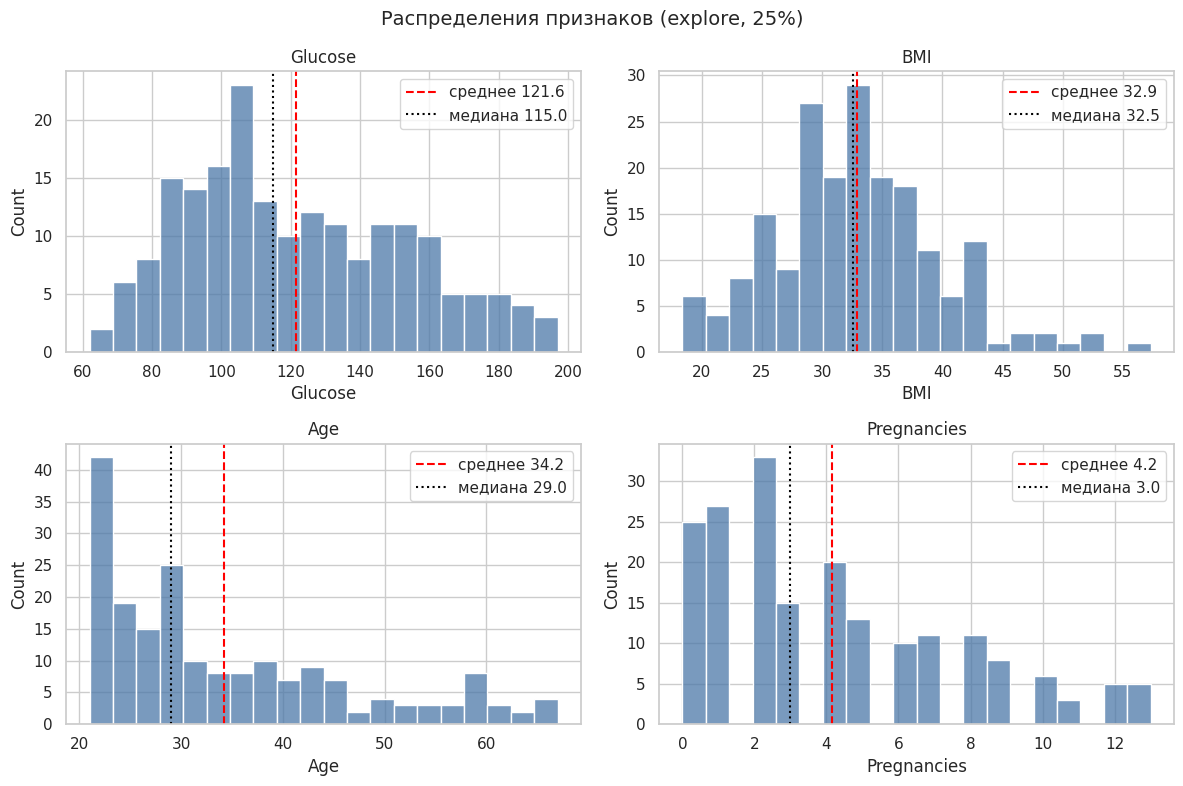

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["Glucose", "BMI", "Age", "Pregnancies"]):
    sns.histplot(explore[col], bins=20, ax=ax, color="#4C78A8")
    ax.axvline(explore[col].mean(), color="red", ls="--", label=f"среднее {explore[col].mean():.1f}")
    ax.axvline(explore[col].median(), color="black", ls=":", label=f"медиана {explore[col].median():.1f}")
    ax.set_title(col); ax.legend()
plt.suptitle("Распределения признаков (explore, 25%)", fontsize=14)
plt.tight_layout(); plt.show()

### График 2. Признаки у здоровых и больных (boxplot по `Outcome`)

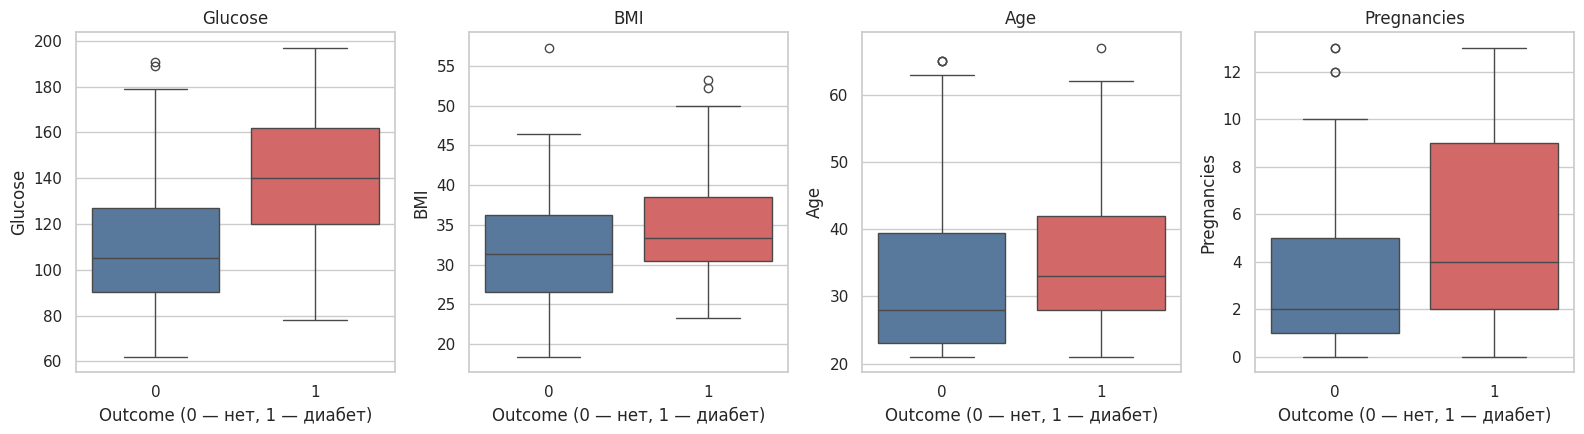

Glucose          BMI          Age        Pregnancies       
           mean median  mean median  mean median        mean median
Outcome                                                            
0         111.1  105.0  31.6   31.3  33.2   28.0         3.5    2.0
1         140.4  140.0  35.2   33.3  36.0   33.0         5.4    4.0

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, col in zip(axes, ["Glucose", "BMI", "Age", "Pregnancies"]):
    sns.boxplot(data=explore, x=TARGET, y=col, hue=TARGET, palette=["#4C78A8", "#E45756"], legend=False, ax=ax)
    ax.set_title(col); ax.set_xlabel("Outcome (0 — нет, 1 — диабет)")
plt.tight_layout(); plt.show()

explore.groupby(TARGET)[["Glucose", "BMI", "Age", "Pregnancies"]].agg(["mean", "median"]).round(1)

### График 3. Доля больных по группам ИМТ и глюкозы

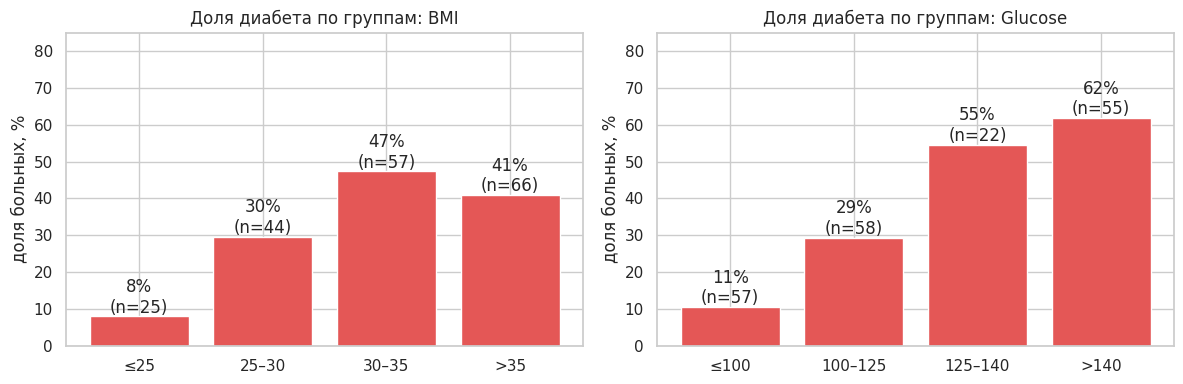

In [7]:
tmp = explore.copy()
tmp["BMI_group"] = pd.cut(tmp["BMI"], [0, 25, 30, 35, 100], labels=["≤25", "25–30", "30–35", ">35"])
tmp["Glucose_group"] = pd.cut(tmp["Glucose"], [0, 100, 125, 140, 300], labels=["≤100", "100–125", "125–140", ">140"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, g in zip(axes, ["BMI_group", "Glucose_group"]):
    t = tmp.groupby(g, observed=True)[TARGET].agg(["mean", "count"])
    ax.bar(t.index.astype(str), t["mean"] * 100, color="#E45756")
    for i, (m, n) in enumerate(zip(t["mean"], t["count"])):
        ax.text(i, m * 100 + 1, f"{m:.0%}\n(n={n})", ha="center")
    ax.set_ylim(0, 85); ax.set_ylabel("доля больных, %"); ax.set_title(f"Доля диабета по группам: {g.replace('_group', '')}")
plt.tight_layout(); plt.show()

### График 4. Возраст и число беременностей

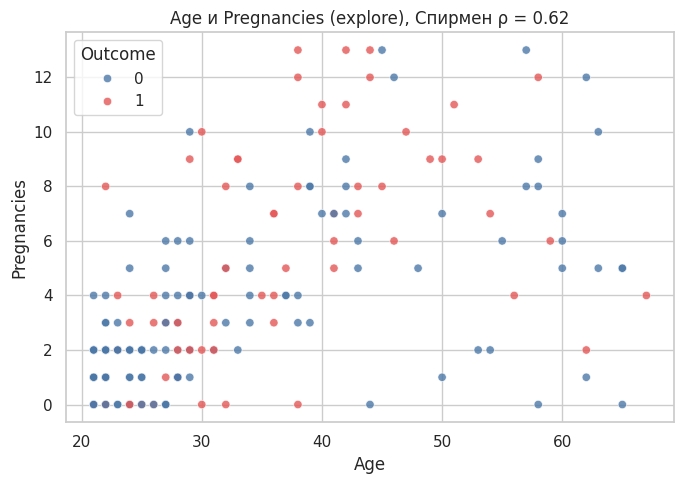

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=explore, x="Age", y="Pregnancies", hue=TARGET, palette=["#4C78A8", "#E45756"], alpha=0.8, ax=ax)
ax.set_title(f"Age и Pregnancies (explore), Спирмен ρ = {explore['Age'].corr(explore['Pregnancies'], method='spearman'):.2f}")
plt.tight_layout(); plt.show()

### Что мы увидели на графиках (наблюдения, ещё не выводы)
- **Boxplot:** ящик глюкозы у больных целиком смещён вверх: медиана около 140 против 105 у здоровых. Выше у больных и `BMI` (среднее 35.2 против 31.6), `Age` (медиана 33 против 28) и `Pregnancies` (медиана 4 против 2).
- **Столбики по группам:** доля больных растёт с ИМТ: примерно 8% при ИМТ ≤ 25 и 47% при ИМТ 30–35 (в первой группе всего 25 человек, поэтому цифра шумная). С глюкозой доля растёт ещё круче: от 11% до 62%.
- **Диаграмма рассеяния:** чем старше пациентка, тем больше у неё беременностей: связь заметная (ρ ≈ 0.5).

## 4. Гипотезы

Для каждой гипотезы: **что увидели → какое предположение сделали → как проверяем → результат на holdout (75%)**. Уровень значимости α = 0.05. Для оценки различий между двумя группами используем критерий Манна–Уитни (не требует нормальности, а у большинства признаков есть правый хвост), для долей — χ² Пирсона. Проверок четыре, поэтому для надёжности смотрим и на более строгий порог α/4 = 0.0125 (поправка Бонферрони).

### Гипотеза 1. У пациенток с диабетом уровень глюкозы выше
**Ход мысли.** На boxplot (график 2) ящик глюкозы у больных почти не пересекается с ящиком здоровых: медианы 140 и 105. А на графике 3 доля больных растёт от 11% до 62% по мере роста глюкозы. Клинически это ожидаемо — глюкоза и есть основной диагностический показатель, поэтому предполагаем, что на новых данных картина повторится.

**H0:** распределения глюкозы в группах одинаковы. **H1:** у больных глюкоза выше.

In [9]:
def compare_groups(data, col):
    a = data.loc[data[TARGET] == 1, col]; b = data.loc[data[TARGET] == 0, col]
    p = stats.mannwhitneyu(a, b, alternative="greater").pvalue
    return pd.Series({"медиана больных": a.median(), "медиана здоровых": b.median(),
                      "среднее больных": a.mean(), "среднее здоровых": b.mean(), "p-value": p})

print("Holdout, n =", len(holdout))
res = compare_groups(holdout, "Glucose")
display(res.drop("p-value").round(1).to_frame("holdout").T)
print(f"p-value (Манн–Уитни, односторонний) = {res['p-value']:.2e}")

Holdout, n = 576


,медиана больных,медиана здоровых,среднее больных,среднее здоровых
holdout,139.0,108.0,142.7,110.6


p-value (Манн–Уитни, односторонний) = 2.52e-32


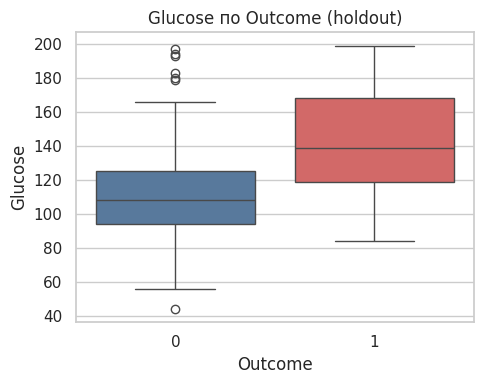

In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=holdout, x=TARGET, y="Glucose", hue=TARGET, palette=["#4C78A8", "#E45756"], legend=False, ax=ax)
ax.set_title("Glucose по Outcome (holdout)"); plt.tight_layout(); plt.show()

**Результат: гипотеза подтверждена.** На holdout медианы 108 (здоровые) и 139 (больные), p ≈ 3·10⁻³², то есть разница намного значимее порога. Результат повторился на данных, которые мы не использовали при поиске гипотезы.

### Гипотеза 2. Ожирение (ИМТ ≥ 30) повышает долю больных
**Ход мысли.** На графике 3 доля больных при ИМТ ≤ 25 около 8%, при 25–30 около 30%, при ИМТ выше 30 — 41–47%. Заметна ступенька около 30 — это и клиническая граница ожирения. Предполагаем, что у пациенток с ИМТ ≥ 30 доля диабета выше, чем у пациенток с ИМТ < 30.

**H0:** доля больных не зависит от группы (ИМТ ≥ 30 / < 30). **H1:** зависит.

In [11]:
h = holdout.copy()
h["obese"] = np.where(h["BMI"] >= 30, "ИМТ ≥ 30", "ИМТ < 30")
table = pd.crosstab(h["obese"], h[TARGET])
table.columns = ["здоровы", "больны"]
table["n"] = table.sum(axis=1)
table["доля больных"] = (table["больны"] / table["n"]).round(3)
display(table)

chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(h["obese"], h[TARGET]))
share = table["доля больных"]
print(f"χ² = {chi2:.1f}, p-value = {p:.2e}")
print(f"Доля больных: ИМТ ≥ 30 — {share['ИМТ ≥ 30']:.1%}, ИМТ < 30 — {share['ИМТ < 30']:.1%}, "
      f"отношение долей ≈ {share['ИМТ ≥ 30'] / share['ИМТ < 30']:.1f}")

,здоровы,больны,n,доля больных
obese,,,,
ИМТ < 30,186,33,219,0.151
ИМТ ≥ 30,191,166,357,0.465


χ² = 57.9, p-value = 2.74e-14
Доля больных: ИМТ ≥ 30 — 46.5%, ИМТ < 30 — 15.1%, отношение долей ≈ 3.1


**Результат: гипотеза подтверждена.** На holdout доля больных 46.5% при ИМТ ≥ 30 против 15.1% при ИМТ < 30 (разница примерно в 3 раза), p ≈ 3·10⁻¹⁴. Важное уточнение: это связь, а не доказательство причины — мы не знаем, что ещё различает группы (возраст, питание, наследственность).

### Гипотеза 3. Связь «беременности — диабет» объясняется возрастом
**Ход мысли.** На boxplot у больных больше беременностей (медиана 4 против 2). Но график 4 показывает, что число беременностей почти прямо растёт с возрастом (ρ ≈ 0.5), а возраст у больных тоже выше (28 против 33). Возникает подозрение, что это эффект «третьей переменной», как в лекции про парадокс Симпсона и мотивацию пациентов: беременностей больше у старших, а старшие чаще болеют, поэтому `Pregnancies` может не нести собственной информации.

Гипотеза: **внутри одной возрастной группы** (20–30, 30–40, 40+) число беременностей у больных и здоровых не различается, хотя на всей выборке разница есть.

**H0:** внутри возрастной группы распределения `Pregnancies` у больных и здоровых одинаковы.

Вся выборка holdout:


,медиана больных,медиана здоровых,среднее больных,среднее здоровых
всего,4.0,2.0,4.7,3.2


p-value = 4.29e-06
Корреляция Age–Pregnancies (Спирмен): ρ = 0.60, p = 1.2e-58



,n,медиана больных,медиана здоровых,p-value
группа,,,,
21–30,316.0,2.0,2.0,0.305
31–40,118.0,5.0,5.0,0.703
41+,142.0,7.0,7.0,0.506


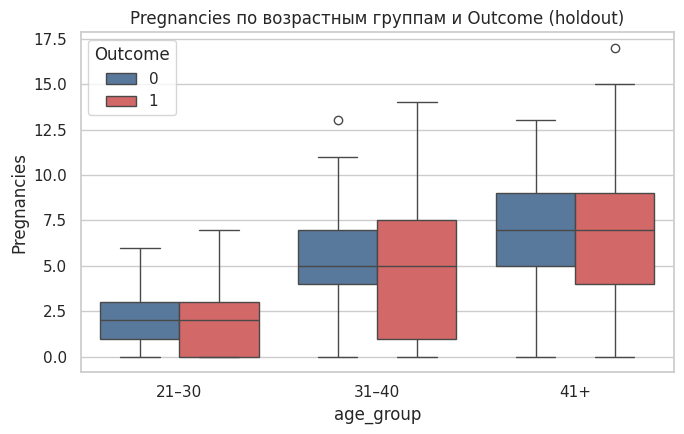

In [12]:
h = holdout.copy()
h["age_group"] = pd.cut(h["Age"], [20, 30, 40, 100], labels=["21–30", "31–40", "41+"])

print("Вся выборка holdout:")
res = compare_groups(h, "Pregnancies")
display(res.drop("p-value").round(1).to_frame("всего").T)
print(f"p-value = {res['p-value']:.2e}")
rho = stats.spearmanr(h["Age"], h["Pregnancies"])
print(f"Корреляция Age–Pregnancies (Спирмен): ρ = {rho.statistic:.2f}, p = {rho.pvalue:.1e}\n")

rows = []
for g, d in h.groupby("age_group", observed=True):
    s = compare_groups(d, "Pregnancies"); s["n"] = len(d); s["группа"] = g
    rows.append(s)
by_age = pd.DataFrame(rows).set_index("группа")
display(by_age[["n", "медиана больных", "медиана здоровых", "p-value"]].round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=h, x="age_group", y="Pregnancies", hue=TARGET, palette=["#4C78A8", "#E45756"], ax=ax)
ax.set_title("Pregnancies по возрастным группам и Outcome (holdout)")
plt.tight_layout(); plt.show()

**Результат: гипотеза подтверждена.** На всей выборке разница значима (p ≈ 4·10⁻⁶), а внутри каждой возрастной группы медианы совпадают (2 и 2, 5 и 5, 7 и 7), p-value 0.31, 0.70 и 0.51. Значит, значимая на первый взгляд связь беременностей с диабетом в основном отражает возраст. Оговорка: возрастные группы грубые, а отсутствие значимости не доказывает полного отсутствия связи (в группах 118–316 человек, маленький эффект мог остаться незамеченным).

### Гипотеза 4. Сам факт пропущенного измерения инсулина не связан с диагнозом
**Ход мысли.** На этапе 2 мы заменили нулевые значения инсулина (около 49% строк) на медиану и добавили флаг `Insulin_was_missing`. На explore доля больных в двух группах флага почти одинакова (35% и 37%). Это ожидаемо, если пропуски появились случайно, и тревожно, если бы они зависели от диагноза. Предполагаем, что флаг пропуска с диагнозом **не связан**. Проверяем и второй флаг, `SkinThickness_was_missing`.

**H0:** доля больных не зависит от значения флага.

In [13]:
for flag in ["Insulin_was_missing", "SkinThickness_was_missing"]:
    t = pd.crosstab(holdout[flag], holdout[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(t)
    shares = t[1] / t.sum(axis=1)
    print(f"{flag}: доля больных при флаге 0 — {shares[0]:.1%}, при флаге 1 — {shares[1]:.1%}; p-value = {p:.3f}")

Insulin_was_missing: доля больных при флаге 0 — 32.3%, при флаге 1 — 37.0%; p-value = 0.281
SkinThickness_was_missing: доля больных при флаге 0 — 32.8%, при флаге 1 — 39.0%; p-value = 0.184


**Результат: H0 не отвергнута.** Для `Insulin_was_missing` доли 32.3% и 37.0% (p ≈ 0.28), для `SkinThickness_was_missing` 32.8% и 39.0% (p ≈ 0.18). Статистически значимой связи с диагнозом нет. Это успокаивает: пропуски не «подсказывают» модели ответ. Но «не обнаружено» не равно «доказано отсутствие»: небольшая разница в долях (5–6 п.п.) могла бы стать значимой на большей выборке.

## 5. Сводка по гипотезам

| № | Гипотеза | Источник идеи | Результат на holdout |
|---|---|---|---|
| 1 | У больных глюкоза выше | boxplot, график 3 | подтверждена, медианы 139 и 108, p ≈ 3·10⁻³² |
| 2 | Доля больных при ИМТ ≥ 30 выше | график 3 | подтверждена, 46.5% против 15.1%, p ≈ 3·10⁻¹⁴ |
| 3 | Связь «беременности — диабет» объясняется возрастом | график 4 + boxplot | подтверждена, внутри возрастных групп различий нет (p ≥ 0.3) |
| 4 | Флаги пропусков не связаны с диагнозом | знание о происхождении данных | не отвергнута (p ≈ 0.28 и 0.18) |

## 6. Вывод

1. **Данные.** На случайных 25% выборки (192 строки) построены четыре графика, посчитаны среднее и медиана. Средние больше медиан у `Age`, `Pregnancies`, `DiabetesPedigreeFunction`, `Glucose` и особенно у `Insulin`, то есть у них правый хвост; поэтому для описания «типичной» пациентки надёжнее медиана.
2. **Главные закономерности.** Диабет сильнее всего связан с глюкозой (разница в медианах около 30 мг/дл) и ИМТ (доля больных при ИМТ ≥ 30 примерно втрое выше). Обе связи, найденные на 25%, воспроизвелись на оставшихся 75%.
3. **Осторожность с интерпретацией.** Число беременностей само по себе выглядит значимым, но почти целиком объясняется возрастом. Для модели это значит, что `Pregnancies` и `Age` частично дублируют друг друга, а для выводов — что на одну парную связь полагаться нельзя.
4. **Качество данных.** Флаги пропусков с диагнозом не связаны, то есть утечки целевой переменной через пропуски нет.
5. **Ограничения.** Все выводы описывают связи, а не причины. Выборка небольшая и состоит только из женщин-пима старше 21 года, так что переносить результат на другие группы нельзя. У `Insulin` и `SkinThickness` значительная доля значений заполнена медианой, поэтому гипотез по ним мы сознательно не строили. Это учебный анализ, а не медицинская диагностика.

**Что дальше (часть 2):** масштабирование и предобработка признаков, чтобы на следующих этапах построить модель классификации.